# Image Data Collection, Processing and Facial Recognition Model

Part 2 of Formative 2 (Group 14). Each member has three photos: neutral, smiling and surprised.

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from src.image_features import (EXPRESSIONS, augment, build_feature_table, detect_face,
                                find_images, load_image)
from src import face_model

IMAGES_DIR = "data/images"
UNAUTHORIZED_DIR = "data/unauthorized/images"
TEST_DIR = "data/test_images"
sns.set_theme(style="whitegrid")

## 1. Load and display the images

In [2]:
images = list(find_images(IMAGES_DIR))
members = sorted({m for m, _, _ in images})
print(f"{len(images)} images from {len(members)} members")
pd.crosstab(pd.Series([m for m, _, _ in images], name="member"),
            pd.Series([e for _, e, _ in images], name="expression"))

12 images from 4 members


expression,neutral,smiling,surprised
member,,,
belyse,1,1,1
kyla,1,1,1
rashid,1,1,1
sandrine,1,1,1


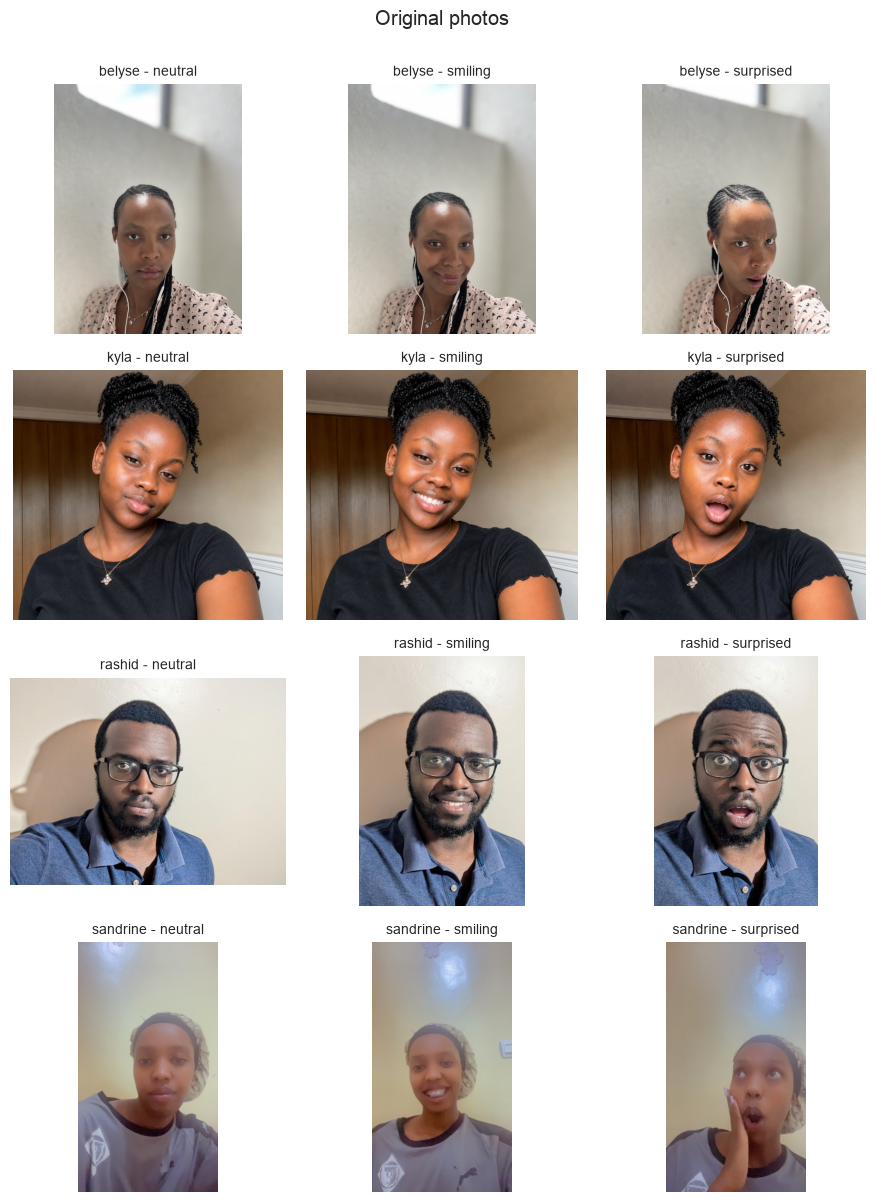

In [3]:
def show(img, ax, title=""):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title, fontsize=10)
    ax.axis("off")

lookup = {(m, e): p for m, e, p in images}
fig, axes = plt.subplots(len(members), 3, figsize=(9, 3 * len(members)), squeeze=False)
for i, m in enumerate(members):
    for j, e in enumerate(EXPRESSIONS):
        if (m, e) in lookup:
            show(load_image(lookup[(m, e)]), axes[i, j], f"{m} - {e}")
        else:
            axes[i, j].axis("off")
plt.suptitle("Original photos", y=1.0)
plt.tight_layout()
plt.show()

## 2. Face detection and alignment

OpenCV's YuNet detector finds the face and five landmarks (eyes, nose, mouth corners). The face is then rotated so the eyes are level and cropped to 112x112, so the background has very little effect.

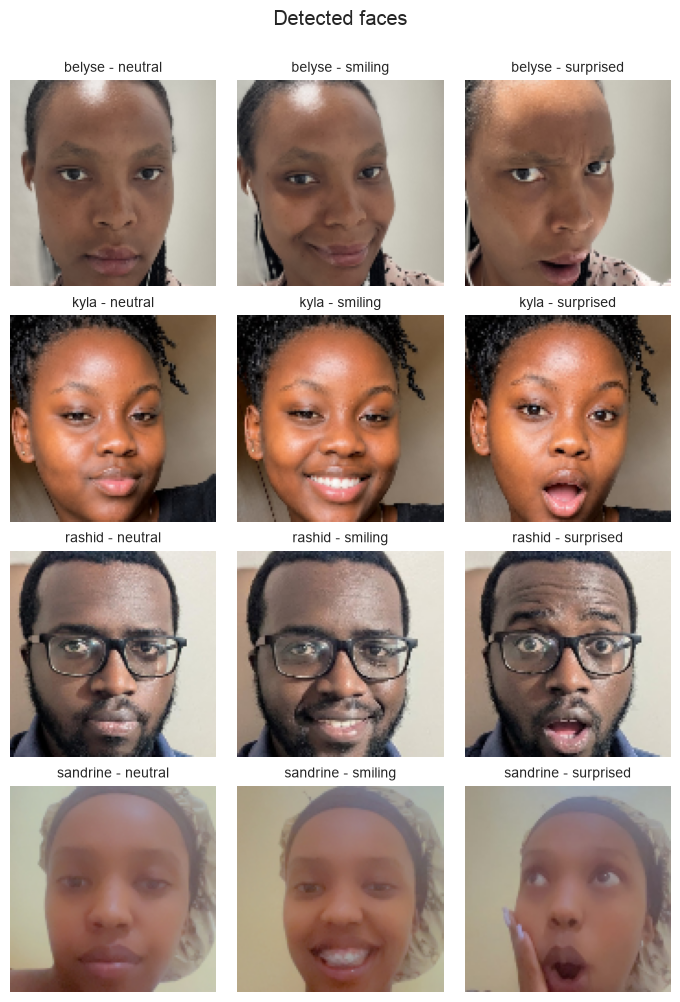

In [4]:
fig, axes = plt.subplots(len(members), 3, figsize=(7, 2.5 * len(members)), squeeze=False)
for i, m in enumerate(members):
    for j, e in enumerate(EXPRESSIONS):
        if (m, e) not in lookup:
            axes[i, j].axis("off")
            continue
        face, found = detect_face(load_image(lookup[(m, e)]))
        show(face, axes[i, j], f"{m} - {e}" + ("" if found else " (no face found)"))
plt.suptitle("Detected faces", y=1.0)
plt.tight_layout()
plt.show()

## 3. Augmentation

Every face crop gets 8 augmented versions: rotation (+15 and -15 degrees), horizontal flip, grayscale, brighter, darker, blur and noise.

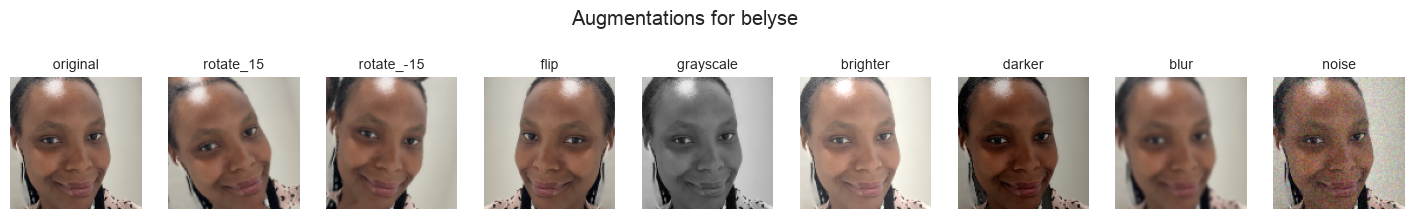

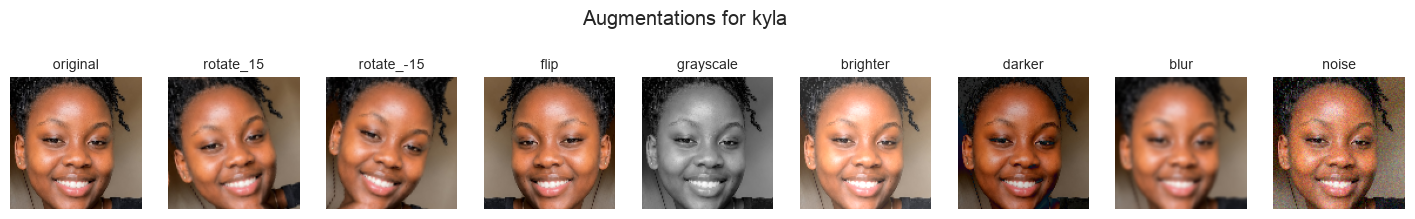

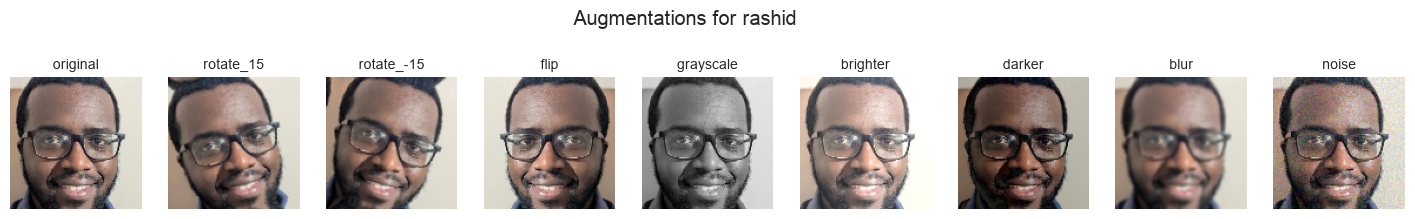

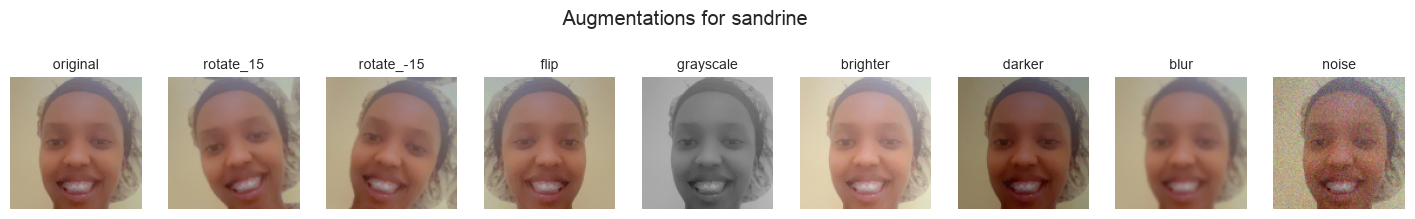

In [5]:
for m in members:
    path = lookup.get((m, "smiling")) or next(p for mm, _, p in images if mm == m)
    face, _ = detect_face(load_image(path))
    versions = augment(face)
    fig, axes = plt.subplots(1, len(versions), figsize=(2 * len(versions), 2.4))
    for ax, (name, img) in zip(axes, versions.items()):
        show(img, ax, name)
    plt.suptitle(f"Augmentations for {m}", y=1.05)
    plt.show()

## 4. Feature extraction

For every version of every face:

- **Face embedding** (128 numbers) from SFace, a face recognition network that comes with OpenCV. Photos of the same person give similar embeddings even with a different pose or lighting.
- HSV colour histograms (16 bins per channel)
- grayscale intensity histogram (32 bins)

The face model uses the embeddings. The histograms are saved as well and compared below.

In [6]:
df = build_feature_table(IMAGES_DIR)
df.to_csv("features/image_features.csv", index=False)
feature_cols = [c for c in df.columns if c not in face_model.META_COLS]
print(f"image_features.csv: {df.shape[0]} rows, {len(feature_cols)} features")
df[face_model.META_COLS + feature_cols[:3]].head()

image_features.csv: 108 rows, 208 features


,member,expression,source_file,augmentation,emb_0,emb_1,emb_2
0,belyse,neutral,data/images/belyse/neutral.jpg,original,0.000311,0.023475,-0.088400
1,belyse,neutral,data/images/belyse/neutral.jpg,rotate_15,0.116528,0.006403,-0.071862
2,belyse,neutral,data/images/belyse/neutral.jpg,rotate_-15,-0.049975,-0.011203,-0.142228
3,belyse,neutral,data/images/belyse/neutral.jpg,flip,0.011168,0.034245,-0.091527
4,belyse,neutral,data/images/belyse/neutral.jpg,grayscale,0.008924,0.029094,-0.115406


In [7]:
df.groupby(["member", "augmentation"]).size().unstack()

augmentation,blur,brighter,darker,flip,grayscale,noise,original,rotate_-15,rotate_15
member,,,,,,,,,
belyse,3,3,3,3,3,3,3,3,3
kyla,3,3,3,3,3,3,3,3,3
rashid,3,3,3,3,3,3,3,3,3
sandrine,3,3,3,3,3,3,3,3,3


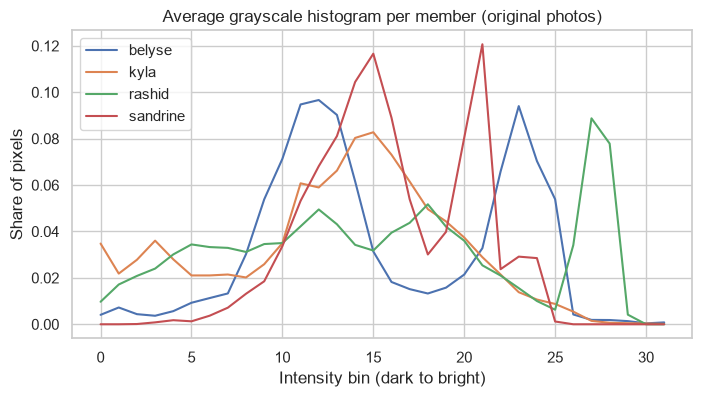

In [8]:
gray_cols = [c for c in feature_cols if c.startswith("hist_gray")]
originals = df[df["augmentation"] == "original"]
fig, ax = plt.subplots(figsize=(8, 4))
for m in members:
    ax.plot(originals.loc[originals["member"] == m, gray_cols].mean().values, label=m)
ax.set_xlabel("Intensity bin (dark to bright)")
ax.set_ylabel("Share of pixels")
ax.set_title("Average grayscale histogram per member (original photos)")
ax.legend()
plt.show()

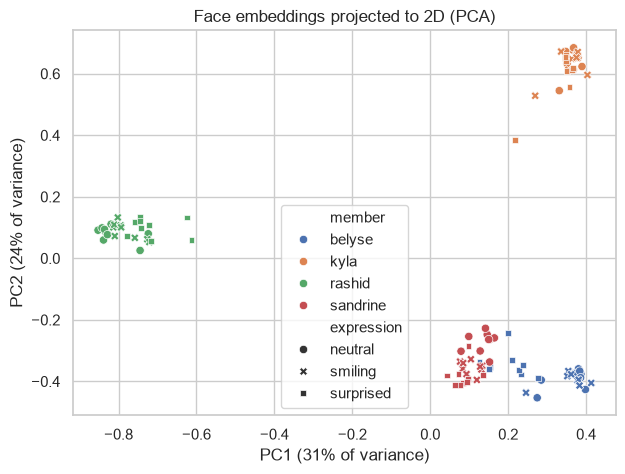

In [9]:
pca = PCA(n_components=2)
emb_cols = [c for c in feature_cols if c.startswith("emb_")]
coords = pca.fit_transform(df[emb_cols])
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=df["member"], style=df["expression"], ax=ax)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
ax.set_title("Face embeddings projected to 2D (PCA)")
plt.show()

## 5. Facial recognition model

Evaluation is leave-one-expression-out: the model is trained on two expressions (with their augmentations) and tested on the third, which it has never seen in any form. This is repeated three times, once per expression.

Three models are compared on accuracy, macro F1 and log loss, using the face embeddings.

In [10]:
results, confidences = face_model.evaluate(df)
results.round(3)

,model,held_out,accuracy,f1,log_loss
0,logistic_regression,neutral,1.000,1.000,0.044
1,logistic_regression,smiling,1.000,1.000,0.041
2,logistic_regression,surprised,1.000,1.000,0.209
3,random_forest,neutral,1.000,1.000,0.241
4,random_forest,smiling,1.000,1.000,0.234
5,random_forest,surprised,0.972,0.972,0.506
6,xgboost,neutral,0.944,0.944,0.158
7,xgboost,smiling,0.972,0.972,0.138
8,xgboost,surprised,0.444,0.407,1.558


In [11]:
summary = results.groupby("model")[["accuracy", "f1", "log_loss"]].mean().round(3)
summary

,accuracy,f1,log_loss
model,,,
logistic_regression,1.000,1.000,0.098
random_forest,0.991,0.991,0.327
xgboost,0.787,0.775,0.618


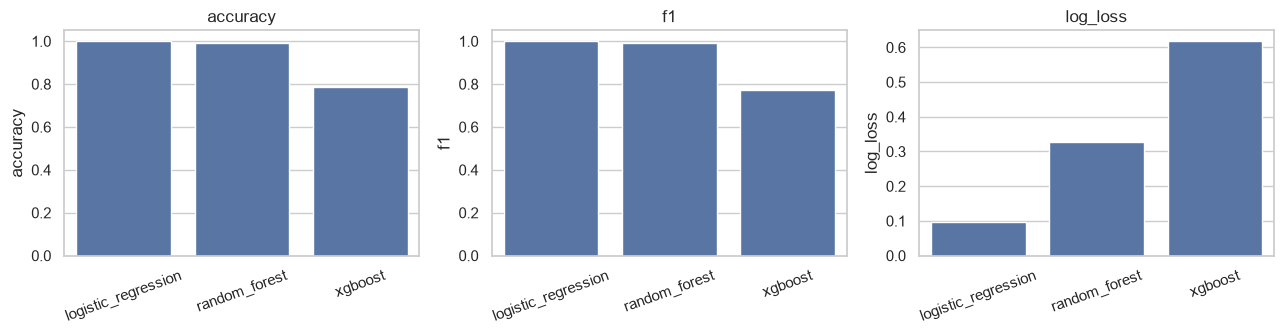

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, metric in zip(axes, ["accuracy", "f1", "log_loss"]):
    sns.barplot(data=results, x="model", y=metric, ax=ax, errorbar=None)
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

Best model: logistic_regression


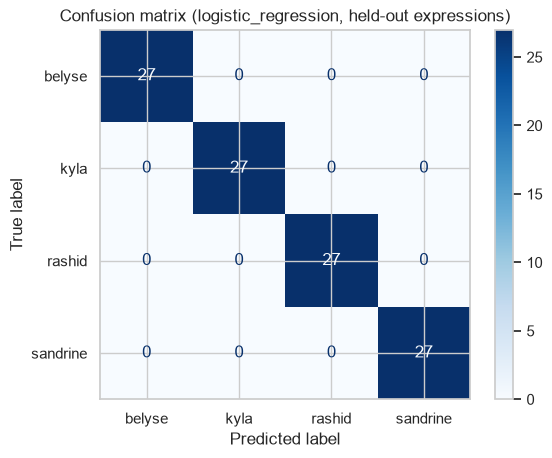

In [13]:
best = summary["f1"].idxmax()
print("Best model:", best)
y_true, y_pred = face_model.held_out_predictions(df, best)
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=members), display_labels=members).plot(cmap="Blues")
plt.title(f"Confusion matrix ({best}, held-out expressions)")
plt.show()

### Embeddings vs histograms

The same evaluation using only the colour/intensity histograms, to compare with the embeddings.

In [14]:
groups = {"embeddings": "emb_", "histograms only": "hist_"}
rows = []
for label, prefix in groups.items():
    cols = [c for c in feature_cols if c.startswith(prefix)]
    res, _ = face_model.evaluate(df, cols)
    s = res.groupby("model")[["accuracy", "f1", "log_loss"]].mean()
    s.insert(0, "features", label)
    rows.append(s)
pd.concat(rows).round(3)

,features,accuracy,f1,log_loss
model,,,,
logistic_regression,embeddings,1.000,1.000,0.098
random_forest,embeddings,0.991,0.991,0.327
xgboost,embeddings,0.787,0.775,0.618
logistic_regression,histograms only,0.926,0.908,0.247
random_forest,histograms only,1.000,1.000,0.272
xgboost,histograms only,0.991,0.991,0.113


## 6. Final model and rejecting unknown faces

A classifier always picks one of the known members, so two checks are used before a face is accepted:

1. the model's confidence must be above a threshold
2. the face embedding must be similar enough (cosine similarity) to that member's own photos

The similarity threshold is set from the training photos only: halfway between the most similar pair of *different* members and the least similar pair of photos of the *same* member (held-out expressions).

Saved models/face_model.pkl (logistic_regression)
Confidence threshold: 0.775
Similarity threshold: 0.568


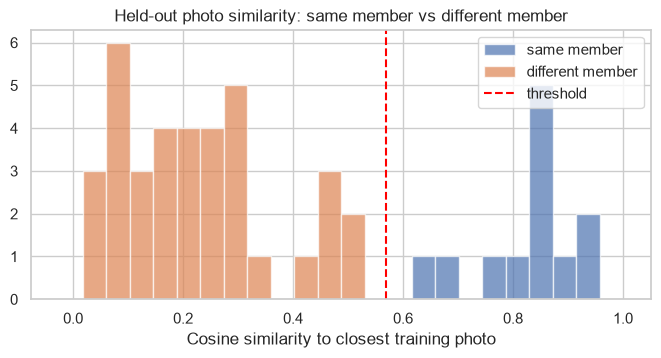

In [15]:
genuine, impostor = face_model.held_out_similarities(df)
bundle = face_model.train_final(df, best, confidences, genuine, impostor)
face_model.save(bundle, "models/face_model.pkl")
print(f"Saved models/face_model.pkl ({best})")
print(f"Confidence threshold: {bundle['threshold']:.3f}")
print(f"Similarity threshold: {bundle['similarity_threshold']:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.linspace(min(impostor.min(), genuine.min()) - 0.05, 1, 25)
ax.hist(genuine, bins=bins, alpha=0.7, label="same member")
ax.hist(impostor, bins=bins, alpha=0.7, label="different member")
ax.axvline(bundle["similarity_threshold"], color="red", linestyle="--", label="threshold")
ax.set_xlabel("Cosine similarity to closest training photo")
ax.set_title("Held-out photo similarity: same member vs different member")
ax.legend()
plt.show()

## 7. Test on photos the model has never seen

- `data/test_images/`: new photos of group members taken on other days, named `<member>_<n>.jpg` (should be accepted as the right person)
- `data/unauthorized/images/`: 15 photos of people outside the group (should all be denied)

In [16]:
def image_files(folder):
    return sorted(os.path.join(folder, f) for f in os.listdir(folder) if f.lower().endswith((".jpg", ".jpeg", ".png")))

tests = [(os.path.basename(p).split("_")[0], p) for p in image_files(TEST_DIR)]
tests += [("outsider", p) for p in image_files(UNAUTHORIZED_DIR)]
rows = []
for expected, path in tests:
    member, conf, sim = face_model.predict_face(path, bundle)
    result = member or "ACCESS DENIED"
    correct = (result == "ACCESS DENIED") if expected == "outsider" else (result == expected)
    rows.append({"photo of": expected, "file": os.path.basename(path), "result": result,
                 "correct": correct, "confidence": round(conf, 3), "similarity": round(sim, 3)})
test_results = pd.DataFrame(rows)
test_results

,photo of,file,result,correct,confidence,similarity
0,belyse,belyse_1.jpg,belyse,True,0.902,0.711
1,belyse,belyse_2.jpg,belyse,True,0.906,0.738
2,sandrine,sandrine_1.jpg,sandrine,True,0.881,0.689
3,outsider,person_01.jpg,ACCESS DENIED,True,0.337,0.371
4,outsider,person_02.jpg,ACCESS DENIED,True,0.463,0.339
5,outsider,person_03.jpg,ACCESS DENIED,True,0.404,0.266
6,outsider,person_04.jpg,ACCESS DENIED,True,0.398,0.339
7,outsider,person_05.jpg,ACCESS DENIED,True,0.326,0.342
8,outsider,person_06.jpg,ACCESS DENIED,True,0.499,0.340
9,outsider,person_07.jpg,ACCESS DENIED,True,0.365,0.299


Members recognised as the right person: 3 / 3
Outsiders denied:                       15 / 15


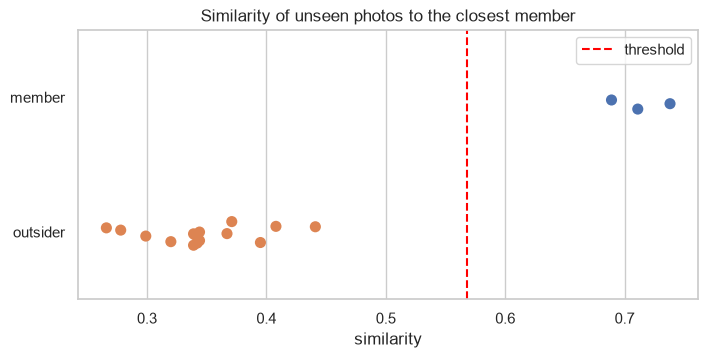

In [17]:
is_member = test_results["photo of"] != "outsider"
print(f"Members recognised as the right person: {test_results[is_member]['correct'].sum()} / {is_member.sum()}")
print(f"Outsiders denied:                       {test_results[~is_member]['correct'].sum()} / {(~is_member).sum()}")

fig, ax = plt.subplots(figsize=(8, 3.5))
group = np.where(is_member, "member", "outsider")
sns.stripplot(x=test_results["similarity"], y=group, hue=group, size=8, ax=ax, legend=False)
ax.axvline(bundle["similarity_threshold"], color="red", linestyle="--", label="threshold")
ax.set_title("Similarity of unseen photos to the closest member")
ax.legend()
plt.show()

## Summary

For my part I worked on the facial images and the face recognition model. Each of us took three photos (neutral, smiling and surprised), but they came in different ways: mine were iPhone HEIC files and Ali's were inside a Word document, with two expressions in one picture. I first had to convert, split and rename everything so every member has the same three files (`neutral.jpg`, `smiling.jpg`, `surprised.jpg`) in their own folder.

The first face detector I used (OpenCV's Haar cascade) failed on my own photos because of the bright window behind me. It cut off my mouth and missed my face completely in one photo, so I switched to the YuNet detector, which found all 12 faces. I made 8 augmented versions of every face (rotation both ways, flip, grayscale, brighter, darker, blur and noise), which gives 108 rows in `image_features.csv`.

My first version used HOG and colour histogram features, and it scored 100% when I trained on two expressions and tested on the third. It looked perfect until I tested it on new photos. Two new selfies of me were rejected, and the model even thought I was Kyla. All three of my training photos were taken in the same place, in the same clothes and at the same time, so the model had learned those photos rather than my face. I switched to face embeddings from SFace, a face recognition network that comes with OpenCV, and kept the histograms in the feature file for comparison.

With embeddings, Logistic Regression got every held-out photo right (accuracy and F1 of 1.0, log loss 0.10). Random Forest was close (0.99) and XGBoost was weaker (0.79), probably because there is so little data. On photos the model had never seen, both new photos of me and a low-quality WhatsApp photo of Sandrine were recognised as the right person, and all 15 photos of people outside the group were denied. Sandrine's photo was a good check because it was a full-body shot where her face is small and blurry, and it was not chosen after seeing any results.

In the full system this model is the first check: if the face is not recognised, the user is denied before the product model or the voice check is reached. Because a classifier always picks someone, a face is only accepted if it is also similar enough to that member's own photos. I set that threshold from the training photos only, so the test photos were not used to tune it. The main thing I learned is that a high score on a small dataset can be misleading. It only became clear once I tested on new photos.